# 09 — Caminho B: Transformer AE com as features da implementação original (J3, J4)

Plano: [PLANO_JUNTAR_DEEP_LEARNING.md](../../PLANO_JUNTAR_DEEP_LEARNING.md), Fase 4. Regras fixadas **antes** do treino
em [PROTOCOLO.md](PROTOCOLO.md), seção 6.

Mesma arquitetura e mesmo treino do `07_transformer_ae` (d = 128, 4 camadas, formulação `masked`, só normais de treino,
parada pela perda nos normais de validação). Muda só o que entra em cada passo da sequência da célula:

| Modelo | Entrada por passo | Dimensões |
|---|---|---|
| **AE-TM** | embedding TerraMind S2 + S1 (é o checkpoint do `07`, sem retreinar) | 384 |
| **AE-ORIG** | as 20 features da implementação original | 20 |
| **AE-TM+ORIG** | as duas concatenadas; perda = 0,5 · MSE(TerraMind) + 0,5 · MSE(originais) | 404 |

Perguntas:
- **J3 / E3:** com o mesmo detector temporal, as features clássicas (AE-ORIG) chegam perto do foundation model (AE-TM)?
- **J4:** juntar na **entrada** (AE-TM+ORIG) é melhor que juntar no **score** (fusão principal do `08`)?

**Fonte:** `tapajos_sub`, avaliação nos blocos de treino em 2023–2025 (**diagnóstico, não reportar**). Rode o `08_fusao`
antes: a comparação com a fusão lê o último run dele.

**Tempo em CPU:** ~30 min por modelo na sub-AOI (medido no `07`). Checkpoints já treinados são reaproveitados
(`REFAZER = False`).

In [1]:
import sys, os, json, time, glob
import numpy as np
import pandas as pd
import config, utils, baselines, modelo, avaliacao
config.make_dirs()
utils.set_seed(config.SEED)

FONTE, AOI = 'tapajos_sub', 'tapajos'
EVAL_SPLIT = 'train' if FONTE.endswith('_sub') else ('test' if AOI == 'tapajos' else 'test_gen')
MODE, D_MODEL, EPOCHS = 'masked', 128, 40          # iguais ao 07 (masked venceu pela perda de validação)
N_TRAIN, N_VAL = 200_000, 50_000
REFAZER = False                                     # True: retreina mesmo se o checkpoint existir
NOMES = {'tm': 'Transformer AE | masked',            # mesmo nome do 07/08, para casar as tabelas
         'orig': 'Transformer AE-ORIG | masked',
         'tm+orig': 'Transformer AE-TM+ORIG | masked'}

def ckpt(entrada):
    if entrada == 'tm':
        return config.CHECKPOINTS_DIR / f'transformer_ae_{MODE}_{FONTE}.pt'      # checkpoint do 07
    return config.CHECKPOINTS_DIR / f'transformer_ae_{MODE}_{entrada.replace("+", "_")}_{FONTE}.pt'

print('avaliação em', EVAL_SPLIT, '(DIAGNÓSTICO, não reportar)' if EVAL_SPLIT == 'train' else '')
run_dir = utils.new_run(f'etapa_ae_combinado_{FONTE}')

avaliação em train (DIAGNÓSTICO, não reportar)


## 1. Amostras

Mesmas amostras do `07` (8 trimestres de histórico). As features originais vêm de `orig_cells` (Fase 1).

In [2]:
s, ctx, lab = baselines.load(FONTE, AOI, k=modelo.K_SEQ)
assert 'orig_cells' in ctx['cells'], 'rode o 08_fusao (ou features_originais.orig_from_cube) antes'
print('amostras a pontuar:', int((s['t'] >= modelo.K_SEQ).sum()), '| treino normal:', int(s['treino_normal'].sum()),
      '| validação normal:', int(s['val_normal'].sum()))

amostras a pontuar: 5120 | treino normal: 544 | validação normal: 116


## 2. Treino (ou carga) dos três modelos

O sorteio das sequências é o mesmo para as três entradas; as que não têm dado original no passo t saem (< 1%).

**Checkpoints:** cada época grava `checkpoints/<modelo>.parcial.pt`. Se o notebook parar no meio (queda de energia, Ctrl+C), basta rodar de novo: o treino continua da última época e chega ao mesmo resultado. Modelos já terminados são carregados direto.

In [3]:
modelos = {}
for entrada in ['tm', 'orig', 'tm+orig']:
    p = ckpt(entrada)
    parcial = p.with_name(p.stem + '.parcial.pt')    # checkpoint de treino, gravado a cada época
    if p.exists() and not REFAZER:
        modelos[entrada] = modelo.Trainer.load(p)
        print(f'== {entrada}: checkpoint carregado ({p.name}, val {modelos[entrada].best_val:.4f})')
        continue
    if REFAZER and parcial.exists():
        parcial.unlink()
    print(f'== {entrada}: treinando' + (' (retomando)' if parcial.exists() else ''))
    tr = modelo.gather_training(s, ctx, 'treino_normal', N_TRAIN, entrada=entrada)
    va = modelo.gather_training(s, ctx, 'val_normal', N_VAL, seed=config.SEED + 1, entrada=entrada)
    print('   treino', tr[0].shape, '| validação', va[0].shape)
    t0 = time.time()
    modelos[entrada] = modelo.Trainer(*tr, *va, mode=MODE, d_model=D_MODEL, epochs=EPOCHS, entrada=entrada,
                                      resume_path=parcial)
    modelos[entrada].save(p)
    modelos[entrada].save(run_dir / p.name)
    parcial.unlink(missing_ok=True)                  # o modelo final está salvo; o parcial não é mais preciso
    print(f'   {(time.time() - t0) / 60:.1f} min nesta sessão, melhor val {modelos[entrada].best_val:.4f}')

== tm: checkpoint carregado (transformer_ae_masked_tapajos_sub.pt, val 0.4101)
== orig: treinando


   treino (26581, 9, 20) | validação (5674, 9, 20)


  época  1: treino 0.5455  val 0.4760  (0.4 min)


  época  2: treino 0.3825  val 0.4037  (0.7 min)


  época  3: treino 0.3562  val 0.3894  (1.2 min)


  época  4: treino 0.3431  val 0.3688  (2.1 min)


... (50 outputs left out)

  época 29: treino 0.3194  val 0.4142  (11.9 min)


  época 30: treino 0.3198  val 0.4169  (12.3 min)


  época 31: treino 0.3183  val 0.4146  (12.7 min)


   12.8 min nesta sessão, melhor val 0.4112


### Curvas de perda

As perdas das três entradas **não são comparáveis entre si** (dimensões e pesos diferentes); servem para ver convergência e sobreajuste.

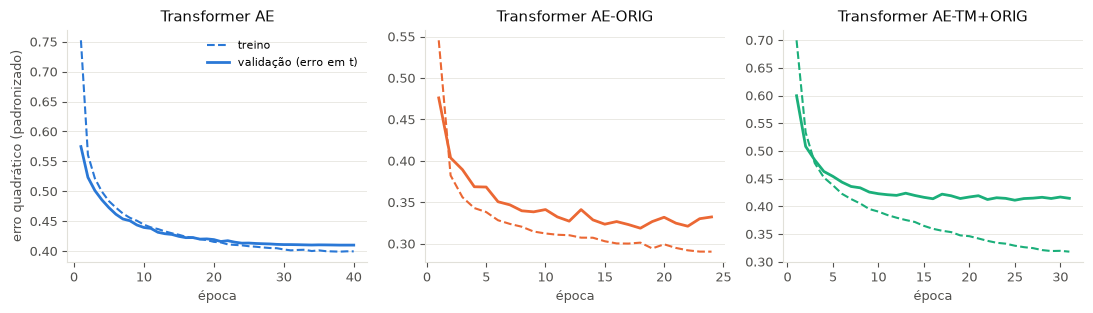

In [4]:
import matplotlib.pyplot as plt
INK, MUTED, GRID = '#0b0b0b', '#52514e', '#e1e0d9'
CAT = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
plt.rcParams.update({'font.size': 9, 'axes.edgecolor': GRID, 'axes.labelcolor': MUTED, 'xtick.color': MUTED,
                     'ytick.color': MUTED, 'axes.spines.top': False, 'axes.spines.right': False})
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, (entrada, t), c in zip(axes, modelos.items(), CAT):
    cv = pd.DataFrame(t.curve)
    if cv.empty:
        ax.set_title(f'{entrada}: sem curva salva'); continue
    ax.plot(cv['epoca'], cv['treino'], color=c, lw=1.5, ls='--', label='treino')
    ax.plot(cv['epoca'], cv['val'], color=c, lw=2, label='validação (erro em t)')
    ax.set_title(NOMES[entrada].replace(' | masked', ''), color=INK); ax.set_xlabel('época')
    ax.grid(axis='y', color=GRID, lw=0.5)
    cv.to_csv(run_dir / f'curva_{entrada.replace("+", "_")}.csv', index=False)
axes[0].set_ylabel('erro quadrático (padronizado)'); axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(run_dir / 'curvas.png', dpi=130); plt.show()

## 3. Pontuação das células

Score do patch = máximo das 49 células (e média, para comparar escalas).

In [5]:
scores = []
for entrada, t in modelos.items():
    t0 = time.time()
    err = modelo.score_all(t, s, ctx, log=False)
    scores.append(modelo.patch_scores(err, s, NOMES[entrada]))
    print(f'{entrada}: {(time.time() - t0) / 60:.1f} min, células sem dado {err.isna().values.mean():.2%}')
scores = pd.concat(scores, axis=1)
rows = s.loc[scores.index]
q = pd.concat([rows[['patch_id', 'step']], scores], axis=1)
q.to_csv(run_dir / 'scores_trimestrais.csv.gz', index=False)

tm: 0.8 min, células sem dado 0.00%


orig: 0.5 min, células sem dado 0.11%


tm+orig: 0.7 min, células sem dado 0.11%


## 4. Avaliação junto com a fusão e os melhores baselines

Lê o último run do `08_fusao` (mesmas amostras) e avalia tudo no mesmo protocolo.

In [6]:
FUSAO = 'Fusão J2 | AE + Original IForest [z_media]'
DSVDD = 'Original | Deep SVDD (20 features + delta)'
KNN_TM = 'TerraMind S2S1 | kNN no delta'
NDVI = 'Espectral | queda de NDVI'
f_run = sorted(glob.glob(str(config.RESULTS_DIR / f'etapa_fusao_{FONTE}' / '*' / 'scores_trimestrais.csv.gz')))[-1]
fus = pd.read_csv(f_run)[['patch_id', 'step', FUSAO, DSVDD, KNN_TM, NDVI]]
tab = q[['patch_id', 'step'] + [c for c in q.columns if not c.endswith('norm. local') and not c.endswith('norm. local [média]')]]
tab = tab.loc[:, ~tab.columns.duplicated()].merge(fus, on=['patch_id', 'step'], how='left')
print('fusão de', f_run, '| amostras', len(tab))

def eval_all(score_df, labels, k):
    out = []
    for col in [c for c in score_df.columns if '|' in c]:
        sc = score_df[['patch_id', k]].assign(score=score_df[col].values).dropna(subset=['score'])
        out.append(avaliacao.evaluate(sc, labels, lab['grade'], key=k, split=EVAL_SPLIT, n_boot=200).assign(metodo=col))
    return pd.concat(out, ignore_index=True)

res_q = eval_all(tab, lab['trim'], 'step').assign(resolucao='trimestral')
anual = tab.assign(year=tab['step'].str[:4].astype(int)).drop(columns='step').groupby(['patch_id', 'year']).max().reset_index()
res_a = eval_all(anual, lab['anual'], 'year').assign(resolucao='anual')
res = pd.concat([res_q, res_a], ignore_index=True)
res['agregacao'] = np.where(res['metodo'].str.endswith('[média]'), 'média', 'máximo')
res['metodo'] = res['metodo'].str.replace(' [média]', '', regex=False)
res.to_csv(run_dir / 'metricas.csv', index=False)

cols = ['AUROC', 'AUROC_lo', 'AUROC_hi', 'AUPRC', 'TPR@1%FPR', 'n_pos']
main = res[(res['agregacao'] == 'máximo') & (res['tarefa'] == 'todos')]
for resol in ['trimestral', 'anual']:
    t = main[main['resolucao'] == resol].set_index('metodo')[cols].sort_values('AUROC', ascending=False)
    print(f'== {resol}, todas as anomalias ({EVAL_SPLIT}, 2023–2025)'); display(t.round(3))

fusão de C:\Users\gabri\Documents\ProjetoGrassQuality\results\etapa_fusao_tapajos_sub\20261104-204250\scores_trimestrais.csv.gz | amostras 5120


== trimestral, todas as anomalias (train, 2023–2025)


,AUROC,AUROC_lo,AUROC_hi,AUPRC,TPR@1%FPR,n_pos
metodo,,,,,,
Original | Deep SVDD (20 features + delta),0.737,0.675,0.815,0.206,0.084,166
TerraMind S2S1 | kNN no delta,0.733,0.630,0.822,0.223,0.090,166
Transformer AE-ORIG | masked,0.721,0.656,0.787,0.136,0.012,166
Transformer AE-TM+ORIG | masked,0.720,0.652,0.795,0.131,0.006,166
Espectral | queda de NDVI,0.714,0.609,0.817,0.216,0.102,166
Fusão J2 | AE + Original IForest [z_media],0.707,0.618,0.793,0.131,0.012,166
Transformer AE | masked,0.684,0.611,0.758,0.132,0.024,166


== anual, todas as anomalias (train, 2023–2025)


,AUROC,AUROC_lo,AUROC_hi,AUPRC,TPR@1%FPR,n_pos
metodo,,,,,,
Original | Deep SVDD (20 features + delta),0.950,0.923,0.973,0.972,0.549,268
Transformer AE-TM+ORIG | masked,0.925,0.888,0.952,0.952,0.284,268
TerraMind S2S1 | kNN no delta,0.899,0.857,0.937,0.943,0.347,268
Transformer AE-ORIG | masked,0.887,0.849,0.921,0.920,0.116,268
Fusão J2 | AE + Original IForest [z_media],0.862,0.802,0.920,0.872,0.004,268
Transformer AE | masked,0.787,0.724,0.844,0.849,0.041,268
Espectral | queda de NDVI,0.768,0.713,0.807,0.856,0.190,268


In [7]:
sel = list(NOMES.values()) + [FUSAO, DSVDD, KNN_TM, NDVI]
qq = res[(res['agregacao'] == 'máximo') & (res['resolucao'] == 'trimestral') & res['metodo'].isin(sel)]
print('== AUROC por tipo, trimestral (máximo das células)')
display(qq.pivot(index='metodo', columns='tarefa', values='AUROC').reindex(sel).round(3))

== AUROC por tipo, trimestral (máximo das células)


tarefa,degradacao,desmatamento,fogo,mineracao,todos
metodo,,,,,
Transformer AE | masked,0.704,0.815,0.677,0.658,0.684
Transformer AE-ORIG | masked,0.716,0.759,0.701,0.787,0.721
Transformer AE-TM+ORIG | masked,0.762,0.766,0.694,0.764,0.720
Fusão J2 | AE + Original IForest [z_media],0.745,0.802,0.687,0.728,0.707
Original | Deep SVDD (20 features + delta),0.770,0.886,0.732,0.670,0.737
TerraMind S2S1 | kNN no delta,0.716,0.891,0.729,0.693,0.733
Espectral | queda de NDVI,0.765,0.764,0.758,0.601,0.714


### Comparações pareadas (mesmos blocos sorteados para os dois métodos)

- AE-TM+ORIG × AE-TM: juntar as features na entrada ajuda o AE? (**J4, principal**)
- AE-TM+ORIG × fusão principal: entrada × score (**J4**)
- AE-ORIG × AE-TM: features clássicas × foundation model, mesmo detector (**J3 / E3**)

In [8]:
def sc(col):
    return tab[['patch_id', 'step']].assign(score=tab[col].values)
pares = [(NOMES['tm+orig'], NOMES['tm']), (NOMES['tm+orig'], FUSAO), (NOMES['orig'], NOMES['tm']),
         (NOMES['tm+orig'], NOMES['orig']), (NOMES['orig'], DSVDD)]
comp = pd.concat([avaliacao.compare(sc(a), sc(b), lab['trim'], lab['grade'], split=EVAL_SPLIT, n_boot=300)
                  .assign(a=a, b=b) for a, b in pares], ignore_index=True)
comp.to_csv(run_dir / 'comparacao_pareada.csv', index=False)
display(comp[comp['tarefa'].isin(['todos', 'desmatamento', 'mineracao', 'fogo', 'degradacao'])]
        .set_index(['a', 'b', 'tarefa'])[['n_pos', 'dAUROC', 'dAUROC_lo', 'dAUROC_hi', 'dAUPRC']].round(3))

n_pos  \
a                               b                                          tarefa                
Transformer AE-TM+ORIG | masked Transformer AE | masked                    todos           166   
                                                                           desmatamento     28   
                                                                           mineracao        34   
                                                                           fogo            102   
                                                                           degradacao       19   
                                Fusão J2 | AE + Original IForest [z_media] todos           166   
                                                                           desmatamento     28   
                                                                           mineracao        34   
                                                                           fogo            102   
                                                                           degradacao       19   
Transformer AE-ORIG | masked    Transformer AE | masked                    todos           166   
                                                                           desmatamento     28   
                                                                           mineracao        34   
                                                                           fogo            102   
                                                                           degradacao       19   
Transformer AE-TM+ORIG | masked Transformer AE-ORIG | masked               todos           166   
                                                                           desmatamento     28   
                                                                           mineracao        34   
                                                                           fogo            102   
                                                                           degradacao       19   
Transformer AE-ORIG | masked    Original | Deep SVDD (20 features + delta) todos           166   
                                                                           desmatamento     28   
                                                                           mineracao        34   
                                                                           fogo            102   
                                                                           degradacao       19   

                                                                                         dAUROC  \
a                               b                                          tarefa                 
Transformer AE-TM+ORIG | masked Transformer AE | masked                    todos          0.036   
                                                                           desmatamento  -0.048   
                                                                           mineracao      0.106   
                                                                           fogo           0.016   
                                                                           degradacao     0.058   
                                Fusão J2 | AE + Original IForest [z_media] todos          0.013   
                                                                           desmatamento  -0.035   
                                                                           mineracao      0.036   
                                                                           fogo           0.006   
                                                                           degradacao     0.017   
Transformer AE-ORIG | masked    Transformer AE | masked                    todos          0.037   
                                                                           desmatamento  -0.056   
                                                        

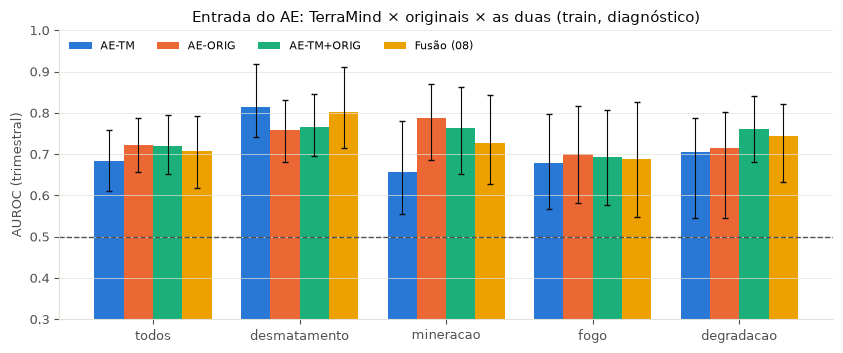

In [9]:
tipos = [t for t in ['todos', 'desmatamento', 'mineracao', 'fogo', 'degradacao'] if t in set(qq['tarefa'])]
mets = {NOMES['tm']: 'AE-TM', NOMES['orig']: 'AE-ORIG', NOMES['tm+orig']: 'AE-TM+ORIG', FUSAO: 'Fusão (08)'}
pv = qq.pivot(index='metodo', columns='tarefa', values='AUROC')
lo = qq.pivot(index='metodo', columns='tarefa', values='AUROC_lo'); hi = qq.pivot(index='metodo', columns='tarefa', values='AUROC_hi')
fig, ax = plt.subplots(figsize=(8.5, 3.6))
w = 0.2
for i, (m, rot) in enumerate(mets.items()):
    x = np.arange(len(tipos)) + (i - 1.5) * w
    v = pv.loc[m, tipos].values
    ax.bar(x, v, w, color=CAT[i], label=rot)
    ax.errorbar(x, v, yerr=[v - lo.loc[m, tipos].values, hi.loc[m, tipos].values - v], fmt='none', ecolor=INK, lw=0.8, capsize=2)
ax.axhline(0.5, color=MUTED, ls='--', lw=1)
ax.set_xticks(np.arange(len(tipos)), tipos); ax.set_ylim(0.3, 1); ax.set_ylabel('AUROC (trimestral)')
ax.grid(axis='y', color=GRID, lw=0.5); ax.legend(frameon=False, fontsize=8, ncol=4, loc='upper left')
ax.set_title(f'Entrada do AE: TerraMind × originais × as duas ({EVAL_SPLIT}, diagnóstico)', color=INK)
fig.tight_layout(); fig.savefig(run_dir / 'auroc_por_tipo.png', dpi=130); plt.show()

In [10]:
resumo = {
    'fonte': FONTE, 'eval_split': EVAL_SPLIT, 'mode': MODE, 'fusao_de': f_run,
    'checkpoints': {e: str(ckpt(e)) for e in modelos},
    'val_loss': {e: round(float(t.best_val), 4) for e, t in modelos.items()},
    'n_train': {e: t.cfg.get('n_train') for e, t in modelos.items()},
    'auroc_todos': {r: main[main['resolucao'] == r].set_index('metodo')['AUROC'].round(4).to_dict() for r in ['trimestral', 'anual']},
    'pareado': comp[comp['tarefa'] == 'todos'][['a', 'b', 'dAUROC', 'dAUROC_lo', 'dAUROC_hi']].round(4).to_dict('records'),
}
(run_dir / 'resumo.json').write_text(json.dumps(resumo, indent=2, ensure_ascii=False), encoding='utf-8')
print('salvo em', run_dir)

salvo em C:\Users\gabri\Documents\ProjetoGrassQuality\results\etapa_ae_combinado_tapajos_sub\20261104-211055


## Leitura (04/11, diagnóstico na sub-AOI — não reportar)

Run: `results/etapa_ae_combinado_tapajos_sub/20261104-211055`. Avaliação no split `train`, 2023–2025, 166 patch-trimestres
com evento. AUROC trimestral, todas as anomalias; IC pareado por bootstrap de blocos.

| Modelo | Todos | Desmat. | Mineração | Fogo | Degradação |
|---|---|---|---|---|---|
| AE-TM (checkpoint do 07) | 0,684 | **0,815** | 0,658 | 0,677 | 0,704 |
| AE-ORIG | **0,721** | 0,759 | **0,787** | 0,701 | 0,716 |
| AE-TM+ORIG | 0,720 | 0,766 | 0,764 | 0,694 | 0,762 |
| Fusão principal (08) | 0,707 | 0,802 | 0,728 | 0,687 | 0,745 |
| Original Deep SVDD (08) | 0,737 | 0,886 | 0,670 | 0,732 | 0,770 |

- **J3 / E3 (features clássicas × foundation model, mesmo AE):** AE-ORIG 0,721 × AE-TM 0,684 (+0,037, IC −0,007 a
  +0,077). Com o mesmo detector temporal, as 20 features originais empatam ou superam o TerraMind. Ganho claro em
  **mineração** (+0,13, IC 0,05 a 0,21); perda em desmatamento (−0,06, IC −0,14 a +0,01).
- **J4 (entrada × score):** AE-TM+ORIG 0,720 × fusão 0,707 (+0,013, IC −0,024 a +0,041): empate. Juntar na entrada
  não ganha de juntar no score.
- **TerraMind sobre as originais:** AE-TM+ORIG ≈ AE-ORIG (−0,001). Dentro do AE, o embedding não acrescenta ao que as
  features originais já dão (talvez em degradação, +0,05, IC largo).
- **Ainda abaixo dos detectores simples:** Original Deep SVDD 0,737 e kNN no delta TerraMind 0,733. Em desmatamento,
  o Deep SVDD original supera o AE-ORIG (+0,13, IC significativo). AUPRC dos AEs (~0,13) < detectores simples (~0,21).
- **Anual:** AE-TM+ORIG 0,925 × AE-TM 0,787.
- **Treino:** AE-ORIG parou na época 24 (melhor na 18), AE-TM+ORIG na 31 (melhor na 25); o AE-TM+ORIG começa a
  sobreajustar (treino cai, validação estabiliza em ~0,41), com só 26,6 mil sequências para 404 dimensões. As perdas
  das três entradas não são comparáveis entre si.
- **Limites:** sub-AOI escolhida pelos rótulos, avaliação no split de treino, poucos positivos por tipo, ICs largos.
  Com mais dados (AOIs completas), o AE-TM+ORIG pode sobreajustar menos.

**Para a Fase 5:** levar AE-TM, AE-ORIG e AE-TM+ORIG para as AOIs completas, com a fusão principal e o Deep SVDD original
como referências. A pergunta do E3 fica em aberto até lá: na sub-AOI, o foundation model não ganhou das features clássicas.